# Data Ingestion, Cleaning & Preprocessing with Pandas
## Retail / E-commerce Orders — End-to-End Data Cleaning Project

**Objective:** Ingest a realistic retail orders dataset (~10,000+ rows) with real-world data-quality problems, systematically clean and preprocess it with **Pandas**, engineer useful features, visualize insights, and export a reliable cleaned dataset for analysis.

**Dataset:** `retail_orders_raw.csv` (raw, preserved as-is) → `clean_dataset.csv` (cleaned output)

**Notebook covers:**
1. Importing libraries & loading data
2. Inspecting rows, columns, dtypes, missing values
3. Data-quality audit **before** cleaning
4. Handling missing values
5. Removing duplicate records
6. Standardizing text & category names
7. Correcting dtypes & invalid dates
8. Detecting & investigating outliers (without blindly deleting valid records)
9. Feature engineering (month/year, profit margin)
10. Before-vs-after comparison
11. Meaningful visualizations
12. Exporting the cleaned dataset

> All paths are **relative** — the notebook runs correctly after cloning the repository.
> All statistics below are computed from the **actual data** at runtime (no hard-coded numbers).


## 0. Import Libraries
Import Pandas, NumPy, Matplotlib and Seaborn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

print("pandas   :", pd.__version__)
print("numpy    :", np.__version__)
import matplotlib
print("matplotlib:", matplotlib.__version__)
print("seaborn  :", sns.__version__)


pandas   : 2.2.3
numpy    : 2.3.5
matplotlib: 3.10.9
seaborn  : 0.13.2


## 1. Load & Inspect the Raw Dataset
Load `retail_orders_raw.csv` using a **relative path** and take a first look.

In [2]:
RAW_PATH = "retail_orders_raw.csv"
CLEAN_PATH = "clean_dataset.csv"

df_raw = pd.read_csv(RAW_PATH)

print(f"Raw dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"Columns ({len(df_raw.columns)}):")
print(list(df_raw.columns))
print("\n--- First 5 rows ---")
display(df_raw.head())
print("\n--- Last 3 rows ---")
display(df_raw.tail(3))
print("\n--- Random 3 rows ---")
display(df_raw.sample(3, random_state=42))


Raw dataset shape: 10,400 rows × 22 columns
Columns (22):
['Order_ID', 'Order_Date', 'Ship_Date', 'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'Region', 'City', 'State', 'Postal_Code', 'Product_ID', 'Category', 'Sub_Category', 'Product_Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping_Cost', 'Order_Priority', 'Payment_Mode']

--- First 5 rows ---


,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Segment,Country,Region,City,State,...,Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Order_Priority,Payment_Mode
0,ORD-2022-106373,2022-11-26,11-27-2022,CUST-11101,Jonathan Rivera,Home Office,United Kingdom,Central,Detroit,MICHIGAN,...,Office Supplies,Binder,Leather Document Folder,$24.11,4,0.0,3.98,7.67,L,Net Banking
1,ORD-2021-108868,2021-12-12,2021-12-17,CUST-12194,Michelle Perez,CONSUMER,Usa,West,Los Angeles,California,...,Office Supplies,Storage,Underbed Storage Box,$86.13,3,0.25,8.94,3.94,Critical,Credti Card
2,ORD-2024-100673,2024-02-28,2024-03-04,CUST-10178,Matthew Wright,Consumer,US,West,San Diego,california,...,Technology,Machines,Laminating Machine,1359.37,2,0.1,40.45,61.60,HIGH,emi
3,ORD-2022-100035,2022/07/20,25-Jul-2022,CUST-10245,Rohan Jones,Consumer,United States,Central,Chicago,Illinois,...,Furniture,Tables,L-Shaped Workstation,122.06,3,0.5,-19.86,6.47,Medium,CC
4,ORD-2021-108287,2021-09-21,2021-09-24,CUST-10128,Ishaan Jones,Consumer,United States,West,mumbai,Maharashtra,...,technologies,PHONE,Bluetooth Headset,112.64,1,0.0,4.16,7.19,Medium,Credti Card



--- Last 3 rows ---


,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Segment,Country,Region,City,State,...,Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Order_Priority,Payment_Mode
10397,ORD-2021-105390,2021-09-29,2021-10-02,CUST-10537,Janet King,Home Office,India,West,San Francisco,California,...,office supplies,supply,Scissors & Cutter Combo,71.09,3,0.0,15.93,10.22,Medium,Credit Card
10398,ORD-2022-100860,2022-05-01,2022-05-11,CUST-11166,ANDREW JONES,Consumer,United Kingdom,South,Chennai,Tamil Nadu,...,tech,Copiers,Refurbished Copier X2,217.4,3,0.3,15.44,15.45,Critical,Debit Card
10399,ORD-2023-107270,2023-08-21,2023-08-25,CUST-11925,Donald Scott,Consumer,USA,Central,Detroit,Michigan,...,Office Supplies,Appliances,Paper Shredder,26.67,2,0.0,6.04,4.20,Medium,Credit Card



--- Random 3 rows ---


,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Segment,Country,Region,City,State,...,Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Order_Priority,Payment_Mode
6373,ORD-2021-104986,08-09-2021,2021-08-18,CUST-11911,Raymond Nelson,Corporate,INDIA,West,San Diego,California,...,TECH,MACHINES,Laminating Machine,382.77,1,0.0,47.59,16.20,Medium,Cash on Delivery
8868,ORD-2023-103762,2023-03-12,2023-03-16,CUST-10392,Brandon Mehta,consumers,united states,EAST,Philadelphia,Pennsylvania,...,Furniture,Tables,Glass Top Coffee Table,192.17,1,0.2,NaN,13.23,High,Credit Card
673,ORD-2023-100014,NaN,2023-05-18,CUST-11997,Steven Iyer,Home Office,U.S.A,South,Vijayawada,Andhra Pradesh,...,Office Supplies,Labels,File Folder Labels,73.1,6,0.0,0.07,6.54,Low,Debit Card


### 1.1 Rows, Columns, Data Types & Missing-Value Counts

In [3]:
print(f"Rows    : {df_raw.shape[0]:,}")
print(f"Columns : {df_raw.shape[1]}")
print("\n--- Data types ---")
print(df_raw.dtypes)
print("\n--- Non-null counts & dtypes (info) ---")
df_raw.info()
print("\n--- Missing-value counts (NaN) ---")
missing = df_raw.isna().sum().sort_values(ascending=False)
print(missing.to_string())
print(f"\nTotal cells        : {df_raw.size:,}")
print(f"Total missing cells: {int(missing.sum()):,} ({missing.sum()/df_raw.size*100:.2f}%)")
print(f"Columns with missing values: {(missing>0).sum()} / {len(missing)}")
print("\n--- Missing % per column (only columns with missing) ---")
print((missing[missing>0]/len(df_raw)*100).round(2).to_string())
print("\n--- Descriptive stats (all columns, raw) ---")
display(df_raw.describe(include="all").T)


Rows    : 10,400
Columns : 22

--- Data types ---
Order_ID           object
Order_Date         object
Ship_Date          object
Customer_ID        object
Customer_Name      object
Segment            object
Country            object
Region             object
City               object
State              object
Postal_Code        object
Product_ID         object
Category           object
Sub_Category       object
Product_Name       object
Sales              object
Quantity           object
Discount           object
Profit             object
Shipping_Cost     float64
Order_Priority     object
Payment_Mode       object
dtype: object

--- Non-null counts & dtypes (info) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10400 entries, 0 to 10399
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        10400 non-null  object 
 1   Order_Date      10268 non-null  object 
 2   Ship_Date       10006 non-nul

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,10400,10000,ORD-2024-108284,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Date,10268,3736,12-31-XXXX,45,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship_Date,10006,3804,31-02-2022,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,10347,2440,CUST-10308,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Name,10209,3697,Frank Wilson,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,10400,23,Consumer,3344,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,10400,28,United States,4273,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,10400,28,South,2539,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,10400,88,Chicago,449,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,10400,72,California,1267,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data-Quality Audit — BEFORE Cleaning
Check duplicates, inconsistent categories, dtype problems, invalid dates and outliers **before** any cleaning. Metrics are stored for the final before/after comparison.

In [4]:
before_metrics = {}
before_metrics["rows"] = len(df_raw)
before_metrics["cols"] = df_raw.shape[1]
before_metrics["duplicate_rows"] = int(df_raw.duplicated().sum())
before_metrics["missing_cells"] = int(df_raw.isna().sum().sum())
before_metrics["missing_pct"] = round(before_metrics["missing_cells"]/df_raw.size*100, 2)
before_metrics["cols_with_missing"] = int((df_raw.isna().sum()>0).sum())

print(f"Duplicate records (exact): {before_metrics['duplicate_rows']:,}")
if before_metrics["duplicate_rows"] > 0:
    print("\nExample duplicated rows (first 3):")
    display(df_raw[df_raw.duplicated(keep="first")].head(3))

cat_cols = ["Segment","Country","Region","Category","Sub_Category","Order_Priority","Payment_Mode"]
print("\n--- Unique-value counts (messy vs expected) ---")
expected = {"Segment":3,"Country":4,"Region":4,"Category":3,"Sub_Category":16,"Order_Priority":4,"Payment_Mode":6}
for c in cat_cols:
    print(f"{c:14s}: {df_raw[c].nunique(dropna=False):3d} unique (expected ~{expected[c]})")
    before_metrics[f"unique_{c}_before"] = int(df_raw[c].nunique(dropna=False))

print("\n--- Top messy Category values (raw) ---")
print(df_raw["Category"].value_counts(dropna=False).head(15).to_string())
print("\n--- Top messy Sub_Category values (raw) ---")
print(df_raw["Sub_Category"].value_counts(dropna=False).head(12).to_string())
print("\n--- Top messy Segment values (raw) ---")
print(df_raw["Segment"].value_counts(dropna=False).head(12).to_string())
print("\n--- Top messy Country values (raw) ---")
print(df_raw["Country"].value_counts(dropna=False).head(12).to_string())
print("\n--- Top messy Payment_Mode values (raw) ---")
print(df_raw["Payment_Mode"].value_counts(dropna=False).head(12).to_string())


Duplicate records (exact): 400

Example duplicated rows (first 3):


,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Segment,Country,Region,City,State,...,Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Order_Priority,Payment_Mode
169,ORD-2024-100487,2024-07-03,2024-07-09,CUST-11714,Robert Smith,Consumer,United States,West,Seattle,Washington,...,Furniture,table,Height-Adjustable Desk,339.63,9,10%,37.57,17.34,Low,CREDIT CARD
322,ORD-2023-103100,NaN,2023-10-02,CUST-12320,emily hill,Corporate,United States,West,Los Angeles,California,...,Technolgy,Machines,Label Printer,883.14,2,0%,68.66,45.43,Low,Net Banking
497,ORD-2024-102894,2024-05-20,2024-05-26,CUST-11316,Varun Young,Consumer,United States,Central,Chicago,ILLINOIS,...,Office Supplies,Fasteners,Binder Clips Assorted,35.22,2,0.0,0.4,5.99,Low,Credti Card



--- Unique-value counts (messy vs expected) ---
Segment       :  23 unique (expected ~3)
Country       :  28 unique (expected ~4)
Region        :  28 unique (expected ~4)
Category      :  26 unique (expected ~3)
Sub_Category  :  94 unique (expected ~16)
Order_Priority:  28 unique (expected ~4)
Payment_Mode  :  41 unique (expected ~6)

--- Top messy Category values (raw) ---
Category
Office Supplies      2759
Furniture            2099
Technology           1916
Office Supply         208
Office-Supplies       195
 Office Supplies      187
office-supplies       186
Furniturre            180
FURNITURES            177
OFFICE SUPPLIES       176
officesupplies        176
Office_Supplies       173
office supplies       167
FURNITURE             164
furniture             157

--- Top messy Sub_Category values (raw) ---


Sub_Category
Bookcases      555
Tables         553
Machines       534
Furnishings    532
Chairs         505
Copiers        495
Accessories    484
Phones         451
Appliances     366
Supplies       365
Storage        364
Envelopes      358

--- Top messy Segment values (raw) ---
Segment
Consumer       3344
Corporate      2188
Home Office    1298
consumer        310
 Consumer       308
CONSUMER        306
Consumer        292
CONSUMER        275
consumers       268
Corporates      191
corporates      188
corporate       184

--- Top messy Country values (raw) ---
Country
United States      4273
India              1268
United Kingdom      673
Canada              669
U.S.A               333
united states       329
U S A               327
USA                 325
US                  319
 UNITED STATES      304
Usa                 285
india               118

--- Top messy Payment_Mode values (raw) ---
Payment_Mode
Credit Card         1812
Cash on Delivery    1250
Debit Card          1239
UP

In [5]:
# --- 2.1 Invalid dates & dtype problems (before cleaning) ---
print("=== Date parsing test (raw strings → datetime, errors coerced) ===")
for col in ["Order_Date", "Ship_Date"]:
    parsed = pd.to_datetime(df_raw[col].astype(str).str.strip(), format="mixed", dayfirst=False, errors="coerce")
    nat = int(parsed.isna().sum())
    print(f"{col}: {nat:,} unparseable/blank ({nat/len(df_raw)*100:.2f}%)")
    before_metrics[f"invalid_{col}_before"] = nat
    print(f"  Invalid examples: {df_raw.loc[parsed.isna(), col].astype(str).value_counts().head(6).to_dict()}")

print("\n=== Numeric dtype problems (raw) ===")
print("Sales dtype:", df_raw["Sales"].dtype, "| examples:", df_raw["Sales"].astype(str).sample(6, random_state=1).tolist())
print("Discount dtype:", df_raw["Discount"].dtype, "| examples:", df_raw["Discount"].astype(str).sample(6, random_state=2).tolist())
print("Quantity dtype:", df_raw["Quantity"].dtype, "| examples:", df_raw["Quantity"].astype(str).sample(6, random_state=3).tolist())
print("Profit dtype:", df_raw["Profit"].dtype, "| examples:", df_raw["Profit"].astype(str).sample(6, random_state=4).tolist())

# Quick numeric preview after coercion (for audit only)
sales_prev = pd.to_numeric(df_raw["Sales"].astype(str).str.replace(r"[$,]", "", regex=True).str.strip(), errors="coerce")
print("\nSales (coerced preview): negative =", int((sales_prev<0).sum()), "| zero =", int((sales_prev==0).sum()),
      "| >20,000 =", int((sales_prev>20000).sum()), "| max =", f"{sales_prev.max():,.2f}", "| min =", f"{sales_prev.min():,.2f}")
before_metrics["sales_negative_before"] = int((sales_prev<0).sum())
before_metrics["sales_zero_before"] = int((sales_prev==0).sum())
before_metrics["sales_extreme_before"] = int((sales_prev>20000).sum())

print("\nbefore_metrics snapshot:")
for k,v in before_metrics.items():
    print(f"  {k}: {v}")


=== Date parsing test (raw strings → datetime, errors coerced) ===


Order_Date: 401 unparseable/blank (3.86%)
  Invalid examples: {'nan': 132, '12-31-XXXX': 45, 'not available': 42, '32/13/2022': 41, '2021-02-30': 39, '2023-13-45': 37}
Ship_Date: 533 unparseable/blank (5.12%)
  Invalid examples: {'nan': 394, '31-02-2022': 51, 'not available': 50, '2023-13-45': 38}

=== Numeric dtype problems (raw) ===
Sales dtype: object | examples: ['27.87', '28.44', '443.44', '365.17', '83317.73', '993.13']
Discount dtype: object | examples: [' 0.0 ', '0.0', '0.3', '0.0', '0.0', '0.1']
Quantity dtype: object | examples: ['5', '1', '3', '2', '3', '3']
Profit dtype: object | examples: ['20.14', '3.26', '4.33', '23.64', '14.98', '338.01']

Sales (coerced preview): negative = 64 | zero = 18 | >20,000 = 80 | max = 119,551.37 | min = -899.34

before_metrics snapshot:
  rows: 10400
  cols: 22
  duplicate_rows: 400
  missing_cells: 2982
  missing_pct: 1.3
  cols_with_missing: 11
  unique_Segment_before: 23
  unique_Country_before: 28
  unique_Region_before: 28
  unique_Categ

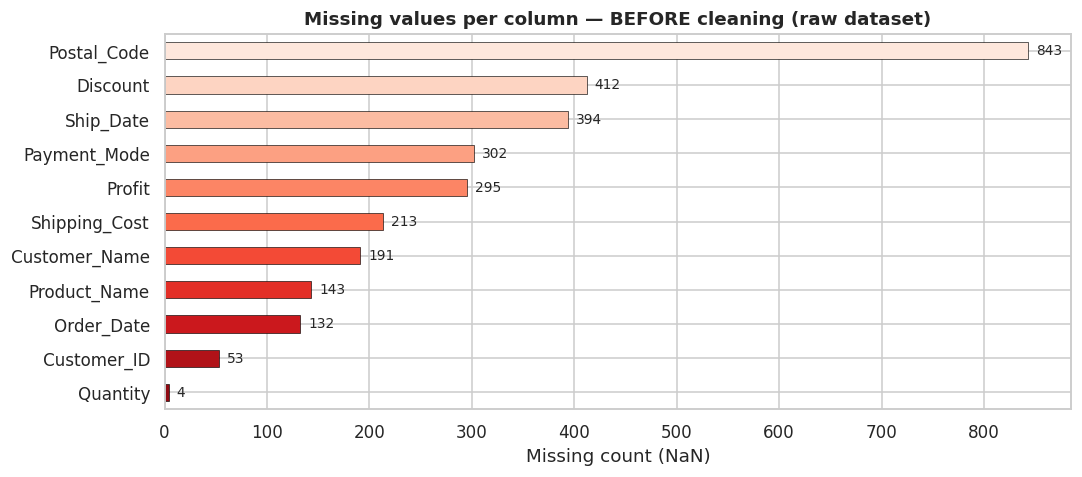

In [6]:
# --- 2.2 Missing-values bar chart (before) ---
miss = df_raw.isna().sum().sort_values(ascending=True)
miss = miss[miss>0]
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = sns.color_palette("Reds_r", len(miss))
miss.plot(kind="barh", ax=ax, color=colors, edgecolor="black", linewidth=0.4)
ax.set_title("Missing values per column — BEFORE cleaning (raw dataset)", fontweight="bold")
ax.set_xlabel("Missing count (NaN)")
for i,v in enumerate(miss.values):
    ax.text(v+8, i, f"{v:,}", va="center", fontsize=9)
plt.tight_layout()
plt.show()


## 3. Handling Missing Values
**Strategy (why each choice is appropriate):**

| Column | Missing handling | Justification |
|---|---|---|
| `Customer_Name` | Fill with `"Unknown"` | Name is descriptive, not analytical — dropping rows would waste valid sales data |
| `Product_Name` | Fill with `"Unknown Product"` | Same — product ID/category still usable |
| `Customer_ID` | Fill with `"UNKNOWN"` | Keeps referential completeness; only ~0.5% affected |
| `Postal_Code` | Invalid tokens (`ABCDE`, `No Zip`, …) → `NaN`, then `"Unknown"` | Postal code is auxiliary; mode-imputation would fabricate geography |
| `Payment_Mode` | Fill with **mode** | Categorical; mode preserves distribution |
| `Discount` | Fill with `0.0` (after numeric cleaning) | Business default = no discount |
| `Profit` | Fill with **median per Category** (after numeric cleaning) | Preserves category-level margin differences |
| `Shipping_Cost` | Fill with **median** | Numeric, mildly skewed — median is robust |
| `Ship_Date` | Fill with `Order_Date + median delay` (after date parsing) | Logical business rule, better than dropping |
| `Order_Date` | **Drop rows** where unparseable | Order date is the primary time key — cannot be imputed reliably |
| `Quantity` word-errors | Coerce → `NaN` → **drop** | Only a handful of rows; quantity is critical |

First: standardize placeholder strings, then apply text-column fills. Numeric/date fills happen after type correction (Sections 6–7).

In [7]:
df = df_raw.copy()
print(f"Working copy: {df.shape[0]:,} rows × {df.shape[1]} columns")

# Standardize common placeholders to NaN (pandas already converts most, this catches stragglers)
df = df.replace(r"^\s*$", np.nan, regex=True)
df = df.replace(["N/A","NULL","n/a","null","N/a","NaN","None","NAN","nan"], np.nan)

print("\nMissing BEFORE handling (working copy):")
print(df.isna().sum()[df.isna().sum()>0].sort_values(ascending=False).to_string())

# --- Text-column fills (safe to do before dedup/typing) ---
df["Customer_Name"] = df["Customer_Name"].fillna("Unknown")
df["Product_Name"] = df["Product_Name"].fillna("Unknown Product")
df["Customer_ID"] = df["Customer_ID"].fillna("UNKNOWN")

# Postal: invalid tokens → NaN → "Unknown"
invalid_postal = ["ABCDE","XXXXX","No Zip","no zip","NO ZIP","12","999999"]
n_invalid_postal = int(df["Postal_Code"].isin(invalid_postal).sum())
df["Postal_Code"] = df["Postal_Code"].replace(invalid_postal, np.nan)
df["Postal_Code"] = df["Postal_Code"].fillna("Unknown").astype(str).str.strip()
print(f"\nInvalid postal tokens converted to 'Unknown': {n_invalid_postal:,}")

# Payment mode → mode
mode_payment = df["Payment_Mode"].mode(dropna=True)[0]
n_pay_fill = int(df["Payment_Mode"].isna().sum())
df["Payment_Mode"] = df["Payment_Mode"].fillna(mode_payment)
print(f"Payment_Mode filled with mode ('{mode_payment}'): {n_pay_fill:,} rows")

print("\nMissing AFTER text-phase handling (numeric/date NaNs intentionally left for Sections 6-7):")
remaining = df.isna().sum()[df.isna().sum()>0].sort_values(ascending=False)
print(remaining.to_string() if len(remaining) else "No missing values remaining.")


Working copy: 10,400 rows × 22 columns

Missing BEFORE handling (working copy):
Postal_Code      843
Discount         412
Ship_Date        394
Payment_Mode     302
Profit           295
Shipping_Cost    213
Customer_Name    191
Product_Name     143
Order_Date       132
Customer_ID       53
Quantity           4

Invalid postal tokens converted to 'Unknown': 237
Payment_Mode filled with mode ('Credit Card'): 302 rows

Missing AFTER text-phase handling (numeric/date NaNs intentionally left for Sections 6-7):
Discount         412
Ship_Date        394
Profit           295
Shipping_Cost    213
Order_Date       132
Quantity           4


## 4. Detecting & Removing Duplicate Records
Exact duplicates (all 22 columns identical) are data-ingestion artifacts. We inspect examples, remove them with `drop_duplicates()`, and verify.

In [8]:
n_dup = int(df.duplicated().sum())
print(f"Exact duplicate rows found: {n_dup:,} ({n_dup/len(df)*100:.2f}% of working data)")
if n_dup > 0:
    print("\nExample duplicates (first 3):")
    display(df[df.duplicated(keep="first")].head(3))

df = df.drop_duplicates().reset_index(drop=True)
print(f"\nShape after drop_duplicates: {df.shape[0]:,} rows × {df.shape[1]} columns (removed {n_dup:,} rows)")
print(f"Verification — duplicates remaining: {int(df.duplicated().sum())}")
assert df.duplicated().sum() == 0, "Duplicates still present!"


Exact duplicate rows found: 400 (3.85% of working data)

Example duplicates (first 3):


,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Segment,Country,Region,City,State,...,Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Order_Priority,Payment_Mode
169,ORD-2024-100487,2024-07-03,2024-07-09,CUST-11714,Robert Smith,Consumer,United States,West,Seattle,Washington,...,Furniture,table,Height-Adjustable Desk,339.63,9,10%,37.57,17.34,Low,CREDIT CARD
322,ORD-2023-103100,NaN,2023-10-02,CUST-12320,emily hill,Corporate,United States,West,Los Angeles,California,...,Technolgy,Machines,Label Printer,883.14,2,0%,68.66,45.43,Low,Net Banking
497,ORD-2024-102894,2024-05-20,2024-05-26,CUST-11316,Varun Young,Consumer,United States,Central,Chicago,ILLINOIS,...,Office Supplies,Fasteners,Binder Clips Assorted,35.22,2,0.0,0.4,5.99,Low,Credti Card



Shape after drop_duplicates: 10,000 rows × 22 columns (removed 400 rows)
Verification — duplicates remaining: 0


## 5. Standardizing Inconsistent Text & Category Names
Raw text has case/spacing/typo variants (e.g. `Furniture` vs `furniture` vs `FURNITURES ` vs `Furniturre`; `Tech` vs `Technology`; `COD` vs `Cash on Delivery`). We normalize with explicit mapping functions so every canonical value is traceable.

In [9]:
# --- 5.1 Mapping functions (explicit & traceable) ---
def std_category(x):
    if pd.isna(x): return x
    k = str(x).strip().lower().replace("_", " ").replace("-", " ")
    k = " ".join(k.split())
    if k in ["furniture", "furnitures", "furniturre"]: return "Furniture"
    if k in ["office supplies", "office supply", "officesupplies"]: return "Office Supplies"
    if k in ["technology", "tech", "technologies", "technolgy"]: return "Technology"
    return str(x).strip().title()

SUB_MAP = {"chair":"Chairs","chairs":"Chairs","table":"Tables","tables":"Tables",
    "bookcase":"Bookcases","bookcases":"Bookcases","furnishing":"Furnishings","furnishings":"Furnishings",
    "storage":"Storage","storages":"Storage","supply":"Supplies","supplies":"Supplies","paper":"Paper","papers":"Paper",
    "binder":"Binders","binders":"Binders","appliance":"Appliances","appliances":"Appliances",
    "envelope":"Envelopes","envelopes":"Envelopes","label":"Labels","labels":"Labels",
    "fastener":"Fasteners","fasteners":"Fasteners","phone":"Phones","phones":"Phones",
    "accessory":"Accessories","accessories":"Accessories","machine":"Machines","machines":"Machines",
    "copier":"Copiers","copiers":"Copiers"}
def std_subcategory(x):
    if pd.isna(x): return x
    k = " ".join(str(x).strip().lower().split())
    return SUB_MAP.get(k, str(x).strip().title())

def std_segment(x):
    if pd.isna(x): return x
    k = " ".join(str(x).strip().lower().replace("_", " ").replace("-", " ").split())
    if k in ["consumer", "consumers"]: return "Consumer"
    if k in ["corporate", "corporates"]: return "Corporate"
    if k in ["home office", "homeoffice"]: return "Home Office"
    return str(x).strip().title()

def std_country(x):
    if pd.isna(x): return x
    k = str(x).strip().lower().replace(".", "").replace(" ", "")
    if k in ["unitedstates", "usa", "us"]: return "United States"
    if k in ["india", "in", "bharat", "ind"]: return "India"
    if k in ["canada", "can", "cananda"]: return "Canada"
    if k in ["unitedkingdom", "uk"]: return "United Kingdom"
    return str(x).strip().title()

def std_region(x):
    if pd.isna(x): return x
    k = " ".join(str(x).strip().lower().split())
    if k in ["east", "eastern", "easts"]: return "East"
    if k in ["west", "western", "wests"]: return "West"
    if k in ["central", "centeral", "centre"]: return "Central"
    if k in ["south", "southern", "souts"]: return "South"
    return str(x).strip().title()

def std_priority(x):
    if pd.isna(x): return x
    k = " ".join(str(x).strip().lower().split())
    if k in ["low", "l"]: return "Low"
    if k in ["medium", "med", "m"]: return "Medium"
    if k in ["high", "h"]: return "High"
    if k in ["critical", "critial", "c"]: return "Critical"
    return str(x).strip().title()

def std_payment(x):
    if pd.isna(x): return x
    k = " ".join(str(x).strip().lower().replace("-", " ").replace(".", "").split())
    if k in ["credit card", "cc", "credti card"]: return "Credit Card"
    if k in ["debit card", "dc"]: return "Debit Card"
    if k in ["cash on delivery", "cod", "c o d"]: return "Cash on Delivery"
    if k == "upi": return "UPI"
    if k in ["emi", "e m i"]: return "EMI"
    if k in ["net banking", "netbanking", "nb"]: return "Net Banking"
    return str(x).strip().title()

# --- 5.2 Apply & compare ---
print("BEFORE standardization (unique counts on working data):")
for c in ["Category","Sub_Category","Segment","Country","Region","Order_Priority","Payment_Mode"]:
    print(f"  {c:14s}: {df[c].nunique(dropna=False)} unique")

df["Category"] = df["Category"].apply(std_category)
df["Sub_Category"] = df["Sub_Category"].apply(std_subcategory)
df["Segment"] = df["Segment"].apply(std_segment)
df["Country"] = df["Country"].apply(std_country)
df["Region"] = df["Region"].apply(std_region)
df["Order_Priority"] = df["Order_Priority"].apply(std_priority)
df["Payment_Mode"] = df["Payment_Mode"].apply(std_payment)

# City / State / Customer_Name: strip + title-case (preserves geography, fixes case/spacing)
for c in ["City", "State", "Customer_Name"]:
    df[c] = df[c].astype(str).str.strip().str.title().replace({"Nan": "Unknown", "nan": "Unknown"})
df.loc[df["Customer_Name"].str.lower()=="unknown", "Customer_Name"] = "Unknown"
df["Customer_ID"] = df["Customer_ID"].astype(str).str.strip()
df["Order_ID"] = df["Order_ID"].astype(str).str.strip()
df["Product_ID"] = df["Product_ID"].astype(str).str.strip()

print("\nAFTER standardization (unique counts):")
for c in ["Category","Sub_Category","Segment","Country","Region","Order_Priority","Payment_Mode"]:
    print(f"  {c:14s}: {df[c].nunique(dropna=False)} unique → {sorted(df[c].unique())}")

print("\n--- Standardized value distributions ---")
print("\nCategory:\n", df["Category"].value_counts().to_string())
print("\nSegment:\n", df["Segment"].value_counts().to_string())
print("\nRegion:\n", df["Region"].value_counts().to_string())
print("\nOrder_Priority:\n", df["Order_Priority"].value_counts().to_string())
print("\nPayment_Mode:\n", df["Payment_Mode"].value_counts().to_string())


BEFORE standardization (unique counts on working data):
  Category      : 26 unique
  Sub_Category  : 94 unique
  Segment       : 23 unique
  Country       : 28 unique
  Region        : 28 unique
  Order_Priority: 28 unique
  Payment_Mode  : 40 unique

AFTER standardization (unique counts):
  Category      : 3 unique → ['Furniture', 'Office Supplies', 'Technology']
  Sub_Category  : 16 unique → ['Accessories', 'Appliances', 'Binders', 'Bookcases', 'Chairs', 'Copiers', 'Envelopes', 'Fasteners', 'Furnishings', 'Labels', 'Machines', 'Paper', 'Phones', 'Storage', 'Supplies', 'Tables']
  Segment       : 3 unique → ['Consumer', 'Corporate', 'Home Office']
  Country       : 4 unique → ['Canada', 'India', 'United Kingdom', 'United States']
  Region        : 4 unique → ['Central', 'East', 'South', 'West']
  Order_Priority: 4 unique → ['Critical', 'High', 'Low', 'Medium']
  Payment_Mode  : 6 unique → ['Cash on Delivery', 'Credit Card', 'Debit Card', 'EMI', 'Net Banking', 'UPI']

--- Standardized

## 6. Correcting Data Types & Invalid Dates
**Problems:** `Sales`/`Profit` contain `"$1,234.56"` strings; `Discount` mixes `0.1` floats with `"10%"` strings; `Quantity` has padded strings and word-numbers (`"two"`); dates use 6+ formats plus invalid values (`2023-13-45`, `not available`). We coerce each to its proper dtype and handle the fallout explicitly.

In [10]:
# --- 6.1 Clean numeric columns ---
# Sales & Profit: strip $, commas, spaces → float
for col in ["Sales", "Profit"]:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(r"[$,]", "", regex=True).str.strip()
        .replace({"": np.nan, "N/A": np.nan, "NULL": np.nan, "nan": np.nan, "None": np.nan}),
        errors="coerce")

# Discount: "10%" → 0.10, plain numbers → float
_raw_disc = df["Discount"].astype(str).str.strip()
_is_pct = _raw_disc.str.endswith("%")
_disc_out = pd.Series(np.nan, index=df.index, dtype=float)
_disc_out[_is_pct] = pd.to_numeric(_raw_disc[_is_pct].str.rstrip("%"), errors="coerce") / 100.0
_disc_out[~_is_pct] = pd.to_numeric(
    _raw_disc[~_is_pct].replace({"": np.nan, "N/A": np.nan, "NULL": np.nan, "nan": np.nan, "None": np.nan}),
    errors="coerce")
df["Discount"] = _disc_out

# Quantity: strip, map word-numbers, → numeric (float first, int after cleaning)
WORD_NUM = {"one":1,"two":2,"three":3,"four":4,"five":5,"six":6,"seven":7,"eight":8,"nine":9,"ten":10}
_qstr = df["Quantity"].astype(str).str.strip()
_qmap = _qstr.str.lower().map(WORD_NUM)
_qnum = pd.to_numeric(_qstr, errors="coerce")
_qnum[_qmap.notna()] = _qmap[_qmap.notna()]
_qnum[_qstr.isin(["", "N/A", "NULL", "nan", "None"])] = np.nan
df["Quantity"] = _qnum

# Shipping_Cost → float
df["Shipping_Cost"] = pd.to_numeric(df["Shipping_Cost"], errors="coerce")

print("Numeric dtypes after cleaning:")
print(df[["Sales","Quantity","Discount","Profit","Shipping_Cost"]].dtypes.to_string())
print("\nNumeric NaNs introduced by coercion (to be handled in §6.3/§7):")
print(df[["Sales","Quantity","Discount","Profit","Shipping_Cost"]].isna().sum().to_string())
print("\nDiscount sanity — min: %.2f | max: %.2f | mean: %.3f" % (df["Discount"].min(), df["Discount"].max(), df["Discount"].mean()))
print("Quantity sanity — unique sorted:", sorted(df["Quantity"].dropna().unique())[:15], "...")


Numeric dtypes after cleaning:
Sales            float64
Quantity         float64
Discount         float64
Profit           float64
Shipping_Cost    float64

Numeric NaNs introduced by coercion (to be handled in §6.3/§7):
Sales              0
Quantity           4
Discount         400
Profit           288
Shipping_Cost    206

Discount sanity — min: -0.30 | max: 1.50 | mean: 0.112
Quantity sanity — unique sorted: [np.float64(-5.0), np.float64(-2.0), np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(55.0), np.float64(74.0)] ...


In [11]:
# --- 6.2 Parse dates with mixed formats ---
df["Order_Date"] = pd.to_datetime(df["Order_Date"].astype(str).str.strip(), format="mixed", dayfirst=False, errors="coerce")
df["Ship_Date"] = pd.to_datetime(df["Ship_Date"].astype(str).str.strip(), format="mixed", dayfirst=False, errors="coerce")

n_bad_order = int(df["Order_Date"].isna().sum())
n_bad_ship = int(df["Ship_Date"].isna().sum())
print(f"Unparseable Order_Date: {n_bad_order:,} ({n_bad_order/len(df)*100:.2f}%) → these rows will be dropped (time key is essential)")
print(f"Unparseable/blank Ship_Date: {n_bad_ship:,} ({n_bad_ship/len(df)*100:.2f}%) → will be imputed with Order_Date + median delay")

# Drop rows without a valid Order_Date
rows_before = len(df)
df = df[df["Order_Date"].notna()].copy().reset_index(drop=True)
print(f"\nDropped {rows_before - len(df):,} rows with invalid Order_Date. Remaining: {len(df):,} rows.")

# Ship-delay analysis on valid pairs
_delay = (df["Ship_Date"] - df["Order_Date"]).dt.days
_valid_delay = _delay[(_delay >= 0) & (_delay <= 30)]
median_delay = int(_valid_delay.median())
print(f"\nValid ship-delay distribution (days): median={median_delay}, mean={_valid_delay.mean():.2f}")
print(_valid_delay.describe().to_string())

# Logic checks on working data (after dropping bad Order_Date rows):
#  1) Ship_Date before Order_Date (data-entry error)
#  2) Ship delay > 30 days (day/month-swap artifact from ambiguous formats; e.g. order Jan-10 with ship parsed as Dec-01)
_delay_all = (df["Ship_Date"] - df["Order_Date"]).dt.days
n_nat = int(df["Ship_Date"].isna().sum())
n_early = int((df["Ship_Date"] < df["Order_Date"]).sum())
n_long = int((_delay_all > 30).sum())
print(f"\nShip_Date blank/unparseable (NaT): {n_nat:,} rows")
print(f"Ship_Date BEFORE Order_Date (logic error): {n_early:,} rows")
print(f"Ship delay >30 days (swap artifact; longest raw delay: {int(_delay_all.max())} days): {n_long:,} rows")
print("Note: delays of 11-30 days are retained as possible (late but plausible) shipments.")

# Fix: NaT + early + long-delay ship dates -> Order_Date + median delay (flagged for traceability)
mask_fix = df["Ship_Date"].isna() | (df["Ship_Date"] < df["Order_Date"]) | (_delay_all > 30)
print(f"\nTotal Ship_Date values to fix: {int(mask_fix.sum()):,} (NaT + early + long-delay, overlaps counted once)")
df["Ship_Date_Fixed"] = False
df.loc[mask_fix, "Ship_Date"] = df.loc[mask_fix, "Order_Date"] + pd.to_timedelta(median_delay, unit="D")
df.loc[mask_fix, "Ship_Date_Fixed"] = True

_fixed_delay = (df["Ship_Date"] - df["Order_Date"]).dt.days
print(f"\nVerification - Order_Date NaT: {int(df['Order_Date'].isna().sum())} | Ship_Date NaT: {int(df['Ship_Date'].isna().sum())}")
print(f"Verification - Ship < Order remaining: {int((df['Ship_Date'] < df['Order_Date']).sum())}")
print(f"Verification - Ship-delay range now: {int(_fixed_delay.min())} to {int(_fixed_delay.max())} days")
print(f"Rows flagged Ship_Date_Fixed=True: {int(df['Ship_Date_Fixed'].sum()):,}")
print(f"Order_Date range: {df['Order_Date'].min().date()} → {df['Order_Date'].max().date()}")
print(f"Ship_Date  range: {df['Ship_Date'].min().date()} → {df['Ship_Date'].max().date()}")


Unparseable Order_Date: 379 (3.79%) → these rows will be dropped (time key is essential)
Unparseable/blank Ship_Date: 509 (5.09%) → will be imputed with Order_Date + median delay

Dropped 379 rows with invalid Order_Date. Remaining: 9,621 rows.

Valid ship-delay distribution (days): median=4, mean=3.92
count    8369.000000
mean        3.919943
std         2.244293
min         0.000000
25%         2.000000
50%         4.000000
75%         5.000000
max        30.000000

Ship_Date blank/unparseable (NaT): 500 rows
Ship_Date BEFORE Order_Date (logic error): 432 rows
Ship delay >30 days (swap artifact; longest raw delay: 325 days): 320 rows
Note: delays of 11-30 days are retained as possible (late but plausible) shipments.

Total Ship_Date values to fix: 1,252 (NaT + early + long-delay, overlaps counted once)

Verification - Order_Date NaT: 0 | Ship_Date NaT: 0
Verification - Ship < Order remaining: 0
Verification - Ship-delay range now: 0 to 30 days
Rows flagged Ship_Date_Fixed=True: 1,252

In [12]:
# --- 6.3 Fill remaining numeric NaNs (after types are correct) ---
print("Missing numeric values before fill:")
print(df[["Discount","Profit","Shipping_Cost"]].isna().sum().to_string())

# Discount NaN → 0.0 (business default: no discount)
df["Discount"] = df["Discount"].fillna(0.0)

# Profit NaN → median per Category (preserves category margins)
profit_medians = df.groupby("Category")["Profit"].median()
print("\nProfit medians per Category used for imputation:")
print(profit_medians.round(2).to_string())
df["Profit"] = df["Profit"].fillna(df.groupby("Category")["Profit"].transform("median"))

# Shipping_Cost NaN → global median
ship_med = float(df["Shipping_Cost"].median())
df["Shipping_Cost"] = df["Shipping_Cost"].fillna(ship_med)
print(f"\nShipping_Cost median used: {ship_med:.2f}")

print("\nMissing after numeric fills:")
print(df[["Sales","Quantity","Discount","Profit","Shipping_Cost","Order_Date","Ship_Date"]].isna().sum().to_string())
print("\nFinal numeric dtypes (Quantity → int after outlier step):")
print(df[["Sales","Quantity","Discount","Profit","Shipping_Cost"]].dtypes.to_string())


Missing numeric values before fill:
Discount         385
Profit           272
Shipping_Cost    202

Profit medians per Category used for imputation:
Category
Furniture           9.60
Office Supplies     5.44
Technology         19.93

Shipping_Cost median used: 10.68

Missing after numeric fills:
Sales            0
Quantity         4
Discount         0
Profit           0
Shipping_Cost    0
Order_Date       0
Ship_Date        0

Final numeric dtypes (Quantity → int after outlier step):
Sales            float64
Quantity         float64
Discount         float64
Profit           float64
Shipping_Cost    float64


## 7. Detecting & Investigating Outliers
We use the **IQR method** plus boxplots/histograms to *detect*, then **investigate** top cases (category, product, quantity, discount) before deciding. Principle: **remove only impossible values** (negative sales, zero/negative quantity, negative or >100% discount); **cap** borderline discounts; **keep but flag** genuine high-value/bulk orders.

Sales    : Q1=     69.32 Q3=    398.78 IQR=    329.46 | bounds=(   -424.87,     892.97) | below=31 above=888
Quantity : Q1=      1.00 Q3=      4.00 IQR=      3.00 | bounds=(     -3.50,       8.50) | below=11 above=301
Discount : Q1=      0.00 Q3=      0.20 IQR=      0.20 | bounds=(     -0.30,       0.50) | below=0 above=91
Profit   : Q1=      0.45 Q3=     28.44 IQR=     27.99 | bounds=(    -41.53,      70.42) | below=478 above=1,021


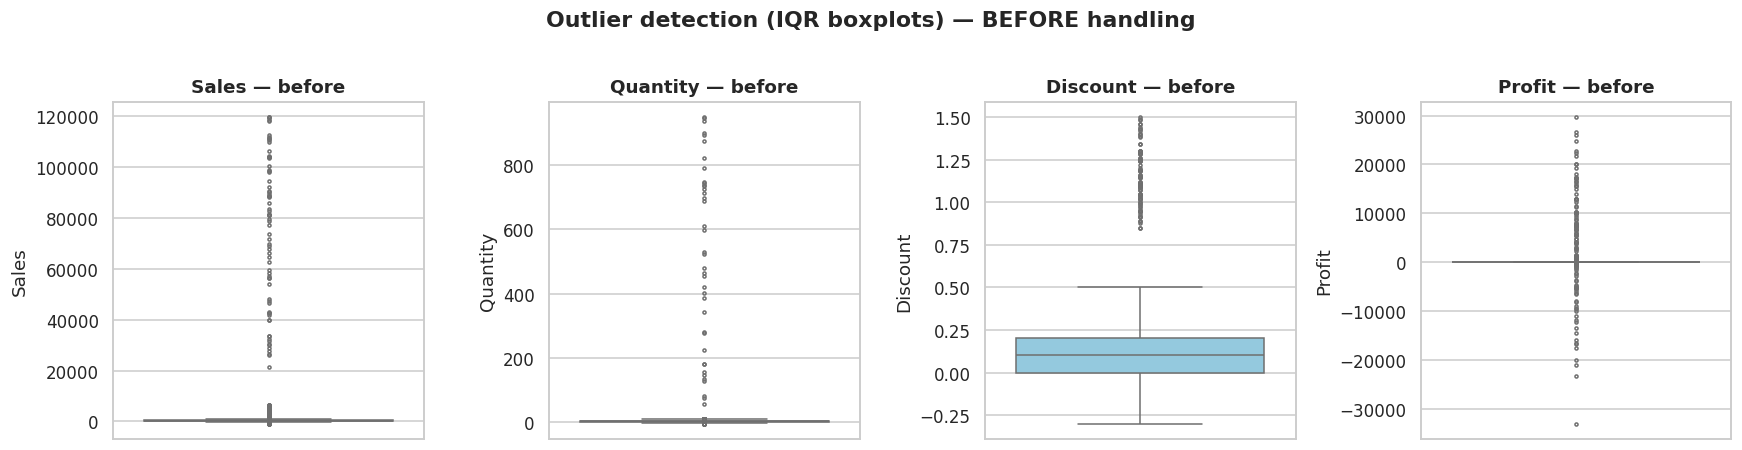

In [13]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return (q1 - 1.5*iqr, q3 + 1.5*iqr, q1, q3, iqr)

for col in ["Sales","Quantity","Discount","Profit"]:
    lo, hi, q1, q3, iqr = iqr_bounds(df[col].dropna())
    n_lo = int((df[col] < lo).sum()); n_hi = int((df[col] > hi).sum())
    print(f"{col:9s}: Q1={q1:>10.2f} Q3={q3:>10.2f} IQR={iqr:>10.2f} | bounds=({lo:>10.2f}, {hi:>10.2f}) | below={n_lo:,} above={n_hi:,}")

# --- Boxplots BEFORE decisions ---
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["Sales","Quantity","Discount","Profit"]):
    sns.boxplot(y=df[col], ax=ax, color="skyblue", fliersize=2)
    ax.set_title(f"{col} — before", fontweight="bold")
plt.suptitle("Outlier detection (IQR boxplots) — BEFORE handling", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


In [14]:
# --- 7.1 Investigate: who are the extreme cases? ---
print("=== TOP 10 Sales (are they plausible bulk/Tech orders?) ===")
display(df.nlargest(10, "Sales")[["Order_ID","Order_Date","Category","Sub_Category","Product_Name","Sales","Quantity","Discount","Profit"]])

print("\n=== TOP 10 Quantity (bulk orders?) ===")
display(df.nlargest(10, "Quantity")[["Order_ID","Category","Sub_Category","Product_Name","Sales","Quantity","Discount","Profit"]])

print("\n=== Impossible Discounts: negative ===")
display(df[df["Discount"]<0][["Order_ID","Category","Sales","Quantity","Discount","Profit"]].head(5))
print(f"Count: {int((df['Discount']<0).sum())}")

print("\n=== Impossible Discounts: >100% ===")
display(df[df["Discount"]>1.0][["Order_ID","Category","Sales","Quantity","Discount","Profit"]].head(5))
print(f"Count >1.0: {int((df['Discount']>1.0).sum())} | Count >0.8: {int((df['Discount']>0.8).sum())}")

print("\n=== Impossible Sales/Quantity: Sales<=0 or Quantity<=0/NaN ===")
bad_sq = df[(df["Sales"]<=0) | (df["Quantity"]<=0) | (df["Quantity"].isna())]
print(f"Rows: {len(bad_sq):,}")
display(bad_sq[["Order_ID","Category","Sales","Quantity","Discount","Profit"]].head(5))

print("\n=== Profit extremes (kept — losses & big wins are analytically valid) ===")
print(df["Profit"].describe().round(2).to_string())


=== TOP 10 Sales (are they plausible bulk/Tech orders?) ===


,Order_ID,Order_Date,Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit
6778,ORD-2021-100785,2021-07-23,Technology,Accessories,Wireless Mouse,119551.37,1.0,0.00,15503.60
4786,ORD-2023-106407,2023-01-28,Technology,Machines,Label Printer,119519.60,4.0,0.30,12258.79
5816,ORD-2021-101518,2021-07-17,Technology,Machines,Laminating Machine,119210.28,1.0,0.00,15039.43
777,ORD-2022-100101,2022-05-28,Furniture,Bookcases,Stackable Cube Shelf,118426.35,1.0,0.20,1226.15
8598,ORD-2022-108519,2022-02-23,Technology,Phones,Bluetooth Headset,117943.00,5.0,0.30,7336.09
6739,ORD-2022-101303,2022-05-24,Office Supplies,Binders,Ring Binders (Pack of 6),112418.05,1.0,0.00,9613.36
4327,ORD-2024-104386,2024-02-04,Technology,Copiers,Multifunction Copier A3,111576.28,8.0,0.00,17058.46
1927,ORD-2023-102236,2023-05-14,Furniture,Tables,L-Shaped Workstation,111171.66,1.0,0.25,-14549.79
9486,ORD-2023-103242,2023-09-15,Office Supplies,Appliances,Electric Kettle 1.8L,110999.06,3.0,0.00,7591.73
5101,ORD-2024-109102,2024-06-08,Office Supplies,Labels,Price Tag Labels,110472.47,1.0,0.10,3915.93



=== TOP 10 Quantity (bulk orders?) ===


,Order_ID,Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit
1426,ORD-2022-106826,Technology,Accessories,Wireless Mouse,157.82,950.0,0.00,22.00
6242,ORD-2024-109040,Technology,Accessories,Mechanical Keyboard,1729.10,947.0,0.20,89.51
9023,ORD-2021-107102,Furniture,Tables,Glass Top Coffee Table,166.51,938.0,0.00,10.67
9593,ORD-2023-100189,Office Supplies,Fasteners,Rubber Bands 1kg,99.41,899.0,0.00,21.05
3456,ORD-2022-108817,Office Supplies,Appliances,Unknown Product,7.24,894.0,0.20,1.25
9235,ORD-2023-105237,Furniture,Chairs,Mesh Back Task Chair,242.94,876.0,0.00,12.04
5437,ORD-2022-108323,Technology,Phones,VoIP Desk Phone,1216.23,823.0,0.15,155.97
6202,ORD-2021-106735,Office Supplies,Labels,File Folder Labels,23.42,790.0,0.00,5.35
4820,ORD-2022-101268,Furniture,Bookcases,Corner Bookshelf Unit,22.80,746.0,0.00,4.30
7697,ORD-2021-109942,Technology,Copiers,Compact Photo Copier,1118.64,745.0,0.00,70.56



=== Impossible Discounts: negative ===


...

Count: 72

=== Impossible Discounts: >100% ===


,Order_ID,Category,Sales,Quantity,Discount,Profit
183,ORD-2022-109334,Furniture,912.01,2.0,1.50,-641.57
226,ORD-2023-108263,Office Supplies,106.86,4.0,1.49,-70.04
233,ORD-2023-103817,Office Supplies,16.39,1.0,1.26,-10.17
283,ORD-2024-106904,Technology,952.03,6.0,1.19,-341.08
381,ORD-2023-104802,Office Supplies,121.79,2.0,1.25,-51.43


Count >1.0: 71 | Count >0.8: 91

=== Impossible Sales/Quantity: Sales<=0 or Quantity<=0/NaN ===
Rows: 101


,Order_ID,Category,Sales,Quantity,Discount,Profit
288,ORD-2024-103000,Office Supplies,-325.38,3.0,0.25,33.160
347,ORD-2024-101963,Office Supplies,-857.55,1.0,0.00,5.445
393,ORD-2023-103872,Furniture,-654.56,3.0,0.00,-107.930
626,ORD-2024-108636,Furniture,350.05,-5.0,0.10,9.980
898,ORD-2023-100003,Technology,-156.82,3.0,0.00,-18.330



=== Profit extremes (kept — losses & big wins are analytically valid) ===
count     9621.00
mean        67.53
std       1344.65
min     -33073.37
25%          0.45
50%          8.42
75%         28.44
max      29715.63


DECISIONS:
  1. DROP Sales<=0 or NaN (a sale of ≤0 is impossible) 
  2. DROP Quantity<=0 or NaN (zero/negative/word-number quantities are invalid)
  3. DROP Discount<0 or Discount>1.0 (negative or >100% discount is impossible)
  4. CAP Discount in (0.8, 1.0] to 0.80 (extreme but borderline → cap, don't drop)
  5. KEEP high Sales (>20k) & bulk Quantity (>20) but FLAG them (valid VIP/bulk orders)
  6. KEEP all Profit values incl. negatives (losses are real business outcomes)

After dropping bad Sales: 9,546 rows (removed 75)
After dropping bad Quantity: 9,520 rows (removed 26)
After dropping impossible Discount: 9,378 rows (removed 142)
Capped Discount (0.8,1.0] → 0.80: 20 rows

Flagged but KEPT — Sales>20,000: 71 rows | Quantity>20: 39 rows

--- Distributions AFTER outlier handling ---


,Sales,Quantity,Discount,Profit
count,9378.00,9378.00,9378.00,9378.00
mean,897.05,5.12,0.10,73.51
std,6940.46,37.71,0.12,1317.86
min,5.00,1.00,0.00,-23241.76
25%,70.72,1.00,0.00,0.71
50%,175.94,2.00,0.10,8.57
75%,402.34,4.00,0.20,28.59
max,119551.37,950.00,0.80,29715.63


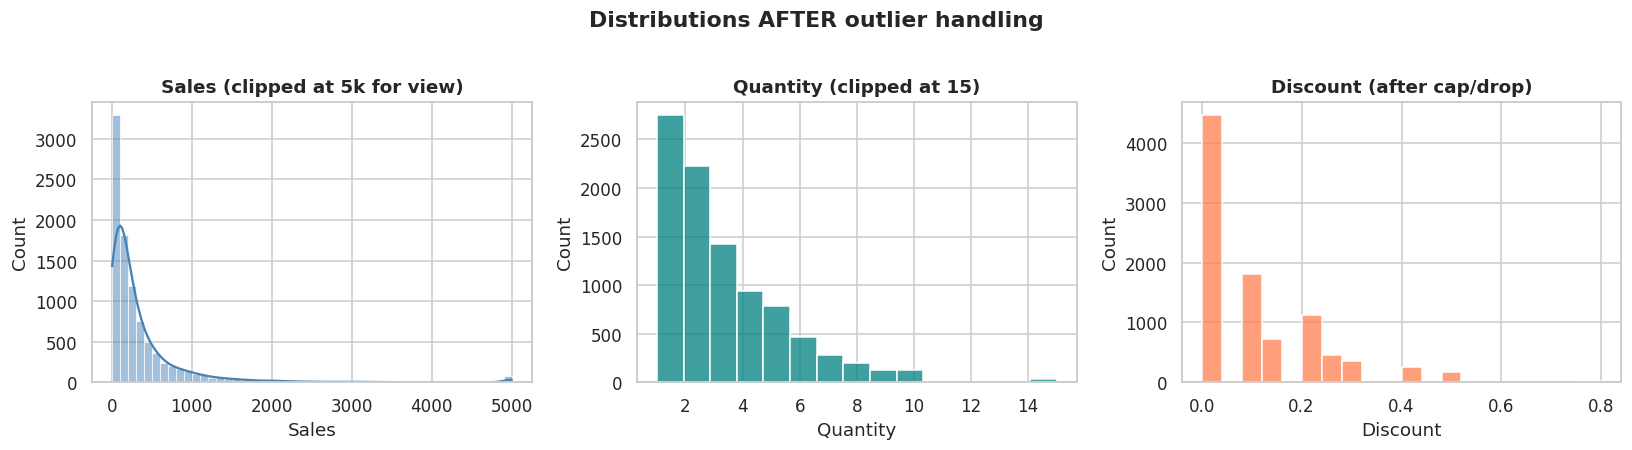

In [15]:
# --- 7.2 Decisions & implementation (documented, not blind) ---
print("DECISIONS:")
print("  1. DROP Sales<=0 or NaN (a sale of ≤0 is impossible) ")
print("  2. DROP Quantity<=0 or NaN (zero/negative/word-number quantities are invalid)")
print("  3. DROP Discount<0 or Discount>1.0 (negative or >100% discount is impossible)")
print("  4. CAP Discount in (0.8, 1.0] to 0.80 (extreme but borderline → cap, don't drop)")
print("  5. KEEP high Sales (>20k) & bulk Quantity (>20) but FLAG them (valid VIP/bulk orders)")
print("  6. KEEP all Profit values incl. negatives (losses are real business outcomes)")

rows0 = len(df)
df = df[~((df["Sales"]<=0) | (df["Sales"].isna()))].copy()
print(f"\nAfter dropping bad Sales: {len(df):,} rows (removed {rows0-len(df):,})")
rows0 = len(df)
df = df[~((df["Quantity"]<=0) | (df["Quantity"].isna()))].copy()
print(f"After dropping bad Quantity: {len(df):,} rows (removed {rows0-len(df):,})")
rows0 = len(df)
df = df[~((df["Discount"]<0) | (df["Discount"]>1.0))].copy()
print(f"After dropping impossible Discount: {len(df):,} rows (removed {rows0-len(df):,})")

n_cap = int(((df["Discount"]>0.8) & (df["Discount"]<=1.0)).sum())
df.loc[(df["Discount"]>0.8)&(df["Discount"]<=1.0), "Discount"] = 0.8
print(f"Capped Discount (0.8,1.0] → 0.80: {n_cap:,} rows")

# Flag (keep) genuine extremes
df["Is_Sales_Outlier"] = df["Sales"] > 20000
df["Is_Qty_Outlier"] = df["Quantity"] > 20
print(f"\nFlagged but KEPT — Sales>20,000: {int(df['Is_Sales_Outlier'].sum()):,} rows | Quantity>20: {int(df['Is_Qty_Outlier'].sum()):,} rows")

# Finalize Quantity as int
df["Quantity"] = df["Quantity"].astype(int)

print("\n--- Distributions AFTER outlier handling ---")
display(df[["Sales","Quantity","Discount","Profit"]].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["Sales"].clip(upper=5000), bins=50, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Sales (clipped at 5k for view)", fontweight="bold")
sns.histplot(df["Quantity"].clip(upper=15), bins=15, kde=False, ax=axes[1], color="teal")
axes[1].set_title("Quantity (clipped at 15)", fontweight="bold")
sns.histplot(df["Discount"], bins=20, kde=False, ax=axes[2], color="coral")
axes[2].set_title("Discount (after cap/drop)", fontweight="bold")
plt.suptitle("Distributions AFTER outlier handling", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


## 8. Feature Engineering
Extract **month/year** from the cleaned date, compute **ship delay** and **profit margin** (`Profit / Sales × 100`, guarded for `Sales > 0`).

New features: Order_Year, Order_Month, Order_Month_Name, Ship_Delay_Days, Profit_Margin_Pct (+ outlier flags)

Order_Year distribution:
Order_Year
2021    2283
2022    2349
2023    2306
2024    2440

Order_Month distribution:
Order_Month
1     773
2     744
3     769
4     770
5     794
6     800
7     776
8     811
9     753
10    793
11    800
12    795

Ship_Delay_Days:
count    9378.00
mean        3.93
std         2.09
min         0.00
25%         2.00
50%         4.00
75%         5.00
max        30.00

Profit_Margin_Pct (%):
count      9378.00
mean         -7.66
std        5059.01
min     -400014.80
25%           0.78
50%           8.10
75%          14.92
max      204851.46

Negative-margin (loss) orders: 2,118 (22.58%)


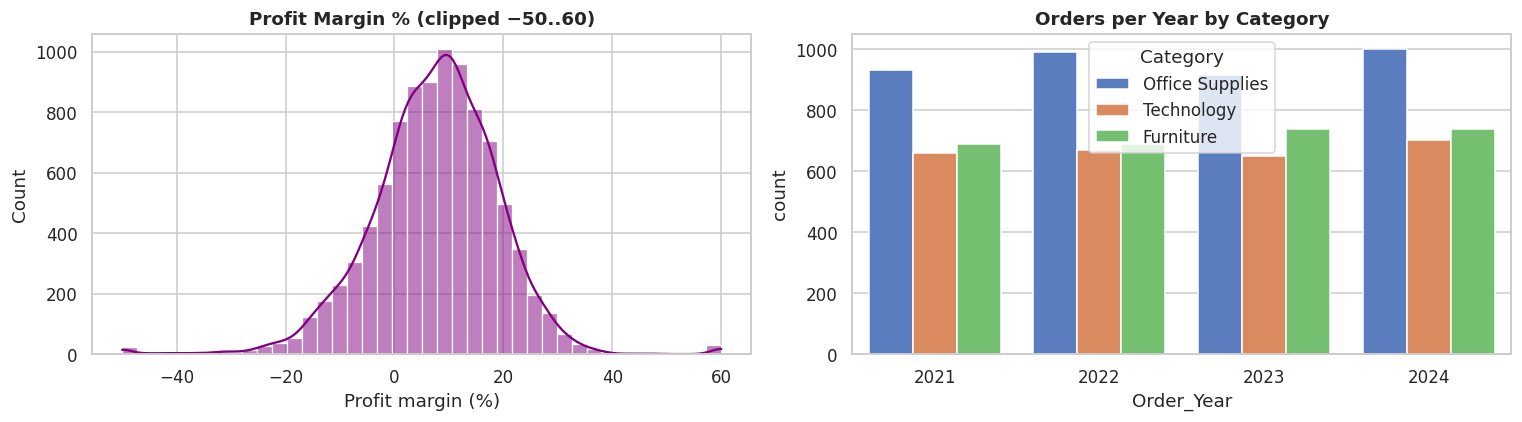

In [16]:
# Month / Year extraction
df["Order_Year"] = df["Order_Date"].dt.year
df["Order_Month"] = df["Order_Date"].dt.month
df["Order_Month_Name"] = df["Order_Date"].dt.strftime("%b")
df["Ship_Delay_Days"] = (df["Ship_Date"] - df["Order_Date"]).dt.days

# Profit margin (%) — correct formula, guarded
df["Profit_Margin_Pct"] = np.where(df["Sales"]>0, df["Profit"]/df["Sales"]*100, np.nan)
df["Profit_Margin_Pct"] = df["Profit_Margin_Pct"].round(2)

print("New features: Order_Year, Order_Month, Order_Month_Name, Ship_Delay_Days, Profit_Margin_Pct (+ outlier flags)")
print("\nOrder_Year distribution:")
print(df["Order_Year"].value_counts().sort_index().to_string())
print("\nOrder_Month distribution:")
print(df["Order_Month"].value_counts().sort_index().to_string())
print("\nShip_Delay_Days:")
print(df["Ship_Delay_Days"].describe().round(2).to_string())
print("\nProfit_Margin_Pct (%):")
print(df["Profit_Margin_Pct"].describe().round(2).to_string())
print(f"\nNegative-margin (loss) orders: {int((df['Profit_Margin_Pct']<0).sum()):,} ({(df['Profit_Margin_Pct']<0).mean()*100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["Profit_Margin_Pct"].clip(-50, 60), bins=40, kde=True, ax=axes[0], color="purple")
axes[0].set_title("Profit Margin % (clipped −50..60)", fontweight="bold")
axes[0].set_xlabel("Profit margin (%)")
sns.countplot(data=df, x="Order_Year", hue="Category", ax=axes[1])
axes[1].set_title("Orders per Year by Category", fontweight="bold")
plt.tight_layout()
plt.show()


## 9. Data-Quality Comparison — BEFORE vs AFTER
All metrics below are computed from the actual raw and cleaned DataFrames.

=========== BEFORE vs AFTER ===========


,BEFORE (raw),AFTER (clean)
Rows,"10,400","9,378"
Columns,22,30
Duplicate rows,400,0
Missing cells,"2,982",0
Missing %,1.3%,0.0%
Cols w/ missing,11,0
Invalid Order_Date,401,0
Invalid Ship_Date,—,0
Category values,26,3
Sub-Category values,94,16



Net: 10,400 → 9,378 rows (1,022 removed = 400 dups + invalid dates/impossible values)


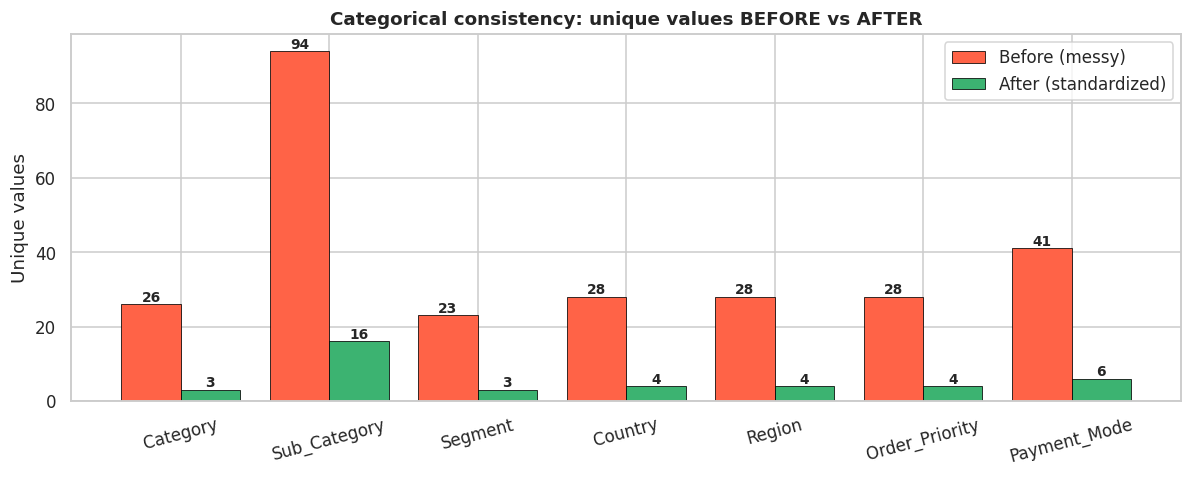

In [17]:
after_metrics = {}
after_metrics["rows"] = len(df)
after_metrics["cols"] = df.shape[1]
after_metrics["duplicate_rows"] = int(df.duplicated().sum())
after_metrics["missing_cells"] = int(df.isna().sum().sum())
after_metrics["missing_pct"] = round(after_metrics["missing_cells"]/df.size*100, 3)
after_metrics["cols_with_missing"] = int((df.isna().sum()>0).sum())
after_metrics["invalid_Order_Date"] = int(df["Order_Date"].isna().sum())
after_metrics["invalid_Ship_Date"] = int(df["Ship_Date"].isna().sum())
after_metrics["sales_negative"] = int((df["Sales"]<=0).sum())
after_metrics["discount_invalid"] = int(((df["Discount"]<0)|(df["Discount"]>1.0)).sum())
for c in ["Segment","Country","Region","Category","Sub_Category","Order_Priority","Payment_Mode"]:
    after_metrics[f"unique_{c}"] = int(df[c].nunique(dropna=False))

comp = pd.DataFrame({
    "BEFORE (raw)": [
        f"{before_metrics['rows']:,}", before_metrics["cols"],
        f"{before_metrics['duplicate_rows']:,}",
        f"{before_metrics['missing_cells']:,}", f"{before_metrics['missing_pct']}%",
        before_metrics["cols_with_missing"],
        f"{before_metrics['invalid_Order_Date_before']:,}", "—",
        before_metrics["unique_Category_before"], before_metrics["unique_Sub_Category_before"],
        before_metrics["unique_Segment_before"], before_metrics["unique_Country_before"],
        before_metrics["unique_Region_before"], before_metrics["unique_Payment_Mode_before"],
        f"{before_metrics['sales_negative_before']:,} neg / {before_metrics['sales_zero_before']:,} zero / {before_metrics['sales_extreme_before']:,} >20k",
        "mixed (object)", "mixed strings"
    ],
    "AFTER (clean)": [
        f"{after_metrics['rows']:,}", after_metrics["cols"],
        f"{after_metrics['duplicate_rows']:,}",
        f"{after_metrics['missing_cells']:,}", f"{after_metrics['missing_pct']}%",
        after_metrics["cols_with_missing"],
        f"{after_metrics['invalid_Order_Date']:,}", f"{after_metrics['invalid_Ship_Date']:,}",
        after_metrics["unique_Category"], after_metrics["unique_Sub_Category"],
        after_metrics["unique_Segment"], after_metrics["unique_Country"],
        after_metrics["unique_Region"], after_metrics["unique_Payment_Mode"],
        f"{after_metrics['sales_negative']:,} ≤0 (flagged kept: {int(df['Is_Sales_Outlier'].sum()):,} >20k)",
        "datetime64", "float/int"
    ]},
    index=["Rows","Columns","Duplicate rows","Missing cells","Missing %","Cols w/ missing",
           "Invalid Order_Date","Invalid Ship_Date","Category values","Sub-Category values",
           "Segment values","Country values","Region values","Payment values",
           "Sales validity","Date dtype","Numeric dtypes"])
print("=========== BEFORE vs AFTER ===========")
display(comp)
print(f"\nNet: {before_metrics['rows']:,} → {after_metrics['rows']:,} rows " +
      f"({before_metrics['rows']-after_metrics['rows']:,} removed = {before_metrics['duplicate_rows']:,} dups + invalid dates/impossible values)")

# Visual comparison: unique-value counts before/after
cats = ["Category","Sub_Category","Segment","Country","Region","Order_Priority","Payment_Mode"]
b_vals = [before_metrics[f"unique_{c}_before"] for c in cats]
a_vals = [after_metrics[f"unique_{c}"] for c in cats]
x = np.arange(len(cats))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(x-0.2, b_vals, 0.4, label="Before (messy)", color="tomato", edgecolor="black", linewidth=0.5)
ax.bar(x+0.2, a_vals, 0.4, label="After (standardized)", color="mediumseagreen", edgecolor="black", linewidth=0.5)
ax.set_xticks(x); ax.set_xticklabels(cats, rotation=15)
ax.set_ylabel("Unique values")
ax.set_title("Categorical consistency: unique values BEFORE vs AFTER", fontweight="bold")
ax.legend()
for i,(b,a) in enumerate(zip(b_vals,a_vals)):
    ax.text(i-0.2, b+0.8, str(b), ha="center", fontsize=9, fontweight="bold")
    ax.text(i+0.2, a+0.8, str(a), ha="center", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()


## 10. Meaningful Visualizations (on Cleaned Data)
Trend, composition and relationship plots that are only trustworthy **after** cleaning.

Monthly aggregates: 48 months from 2021-01-01 to 2024-12-01
Total cleaned Sales: $8,412,524.72 | Total Profit: $689,420.16 | Orders: 9,378


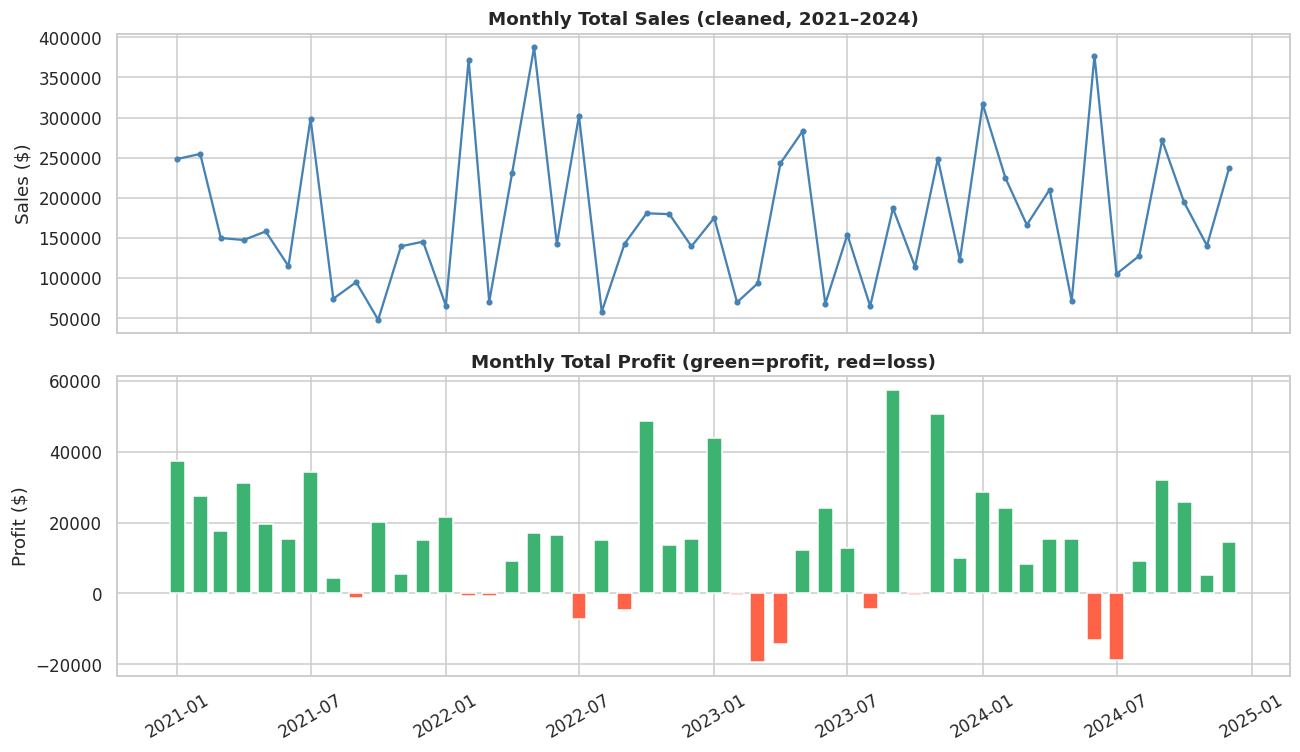

In [18]:
# --- 10.1 Monthly sales & profit trend ---
monthly = df.groupby(["Order_Year","Order_Month"]).agg(Sales=("Sales","sum"), Profit=("Profit","sum"), Orders=("Order_ID","count")).reset_index()
monthly["YM"] = pd.to_datetime(monthly["Order_Year"].astype(str)+"-"+monthly["Order_Month"].astype(str)+"-01")
monthly = monthly.sort_values("YM")
print(f"Monthly aggregates: {len(monthly)} months from {monthly['YM'].min().date()} to {monthly['YM'].max().date()}")
print(f"Total cleaned Sales: ${monthly['Sales'].sum():,.2f} | Total Profit: ${monthly['Profit'].sum():,.2f} | Orders: {monthly['Orders'].sum():,}")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(monthly["YM"], monthly["Sales"], marker="o", markersize=3, color="steelblue", linewidth=1.5)
axes[0].set_title("Monthly Total Sales (cleaned, 2021–2024)", fontweight="bold")
axes[0].set_ylabel("Sales ($)")
axes[1].bar(monthly["YM"], monthly["Profit"], width=20, color=np.where(monthly["Profit"]>=0, "mediumseagreen", "tomato"))
axes[1].set_title("Monthly Total Profit (green=profit, red=loss)", fontweight="bold")
axes[1].set_ylabel("Profit ($)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


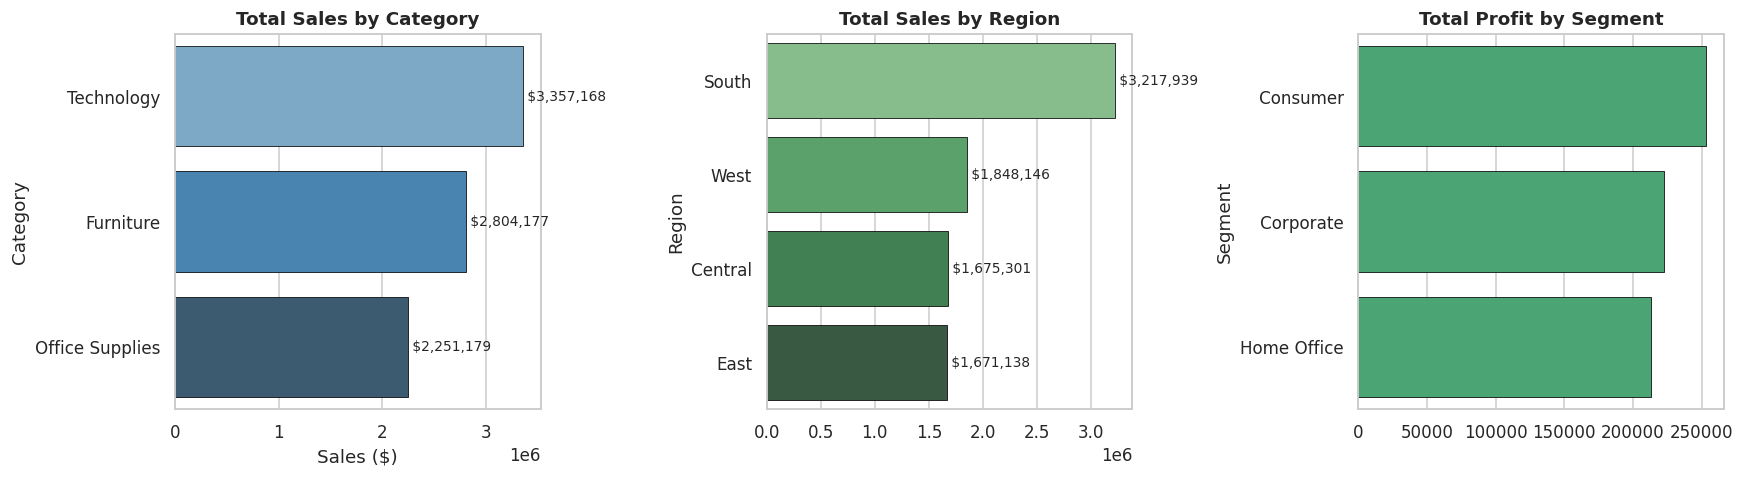

Top 5 Sub-Categories by Sales:
Sub_Category
Machines     1185925.55
Copiers       866274.95
Tables        833182.88
Bookcases     814107.07
Phones        714507.37


In [19]:
# --- 10.2 Sales by Category / Region / Segment ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
cat_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
sns.barplot(x=cat_sales.values, y=cat_sales.index, ax=axes[0], palette="Blues_d", edgecolor="black", linewidth=0.5)
axes[0].set_title("Total Sales by Category", fontweight="bold")
axes[0].set_xlabel("Sales ($)")
for i,v in enumerate(cat_sales.values):
    axes[0].text(v, i, f" ${v:,.0f}", va="center", fontsize=9)

reg_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
sns.barplot(x=reg_sales.values, y=reg_sales.index, ax=axes[1], palette="Greens_d", edgecolor="black", linewidth=0.5)
axes[1].set_title("Total Sales by Region", fontweight="bold")
for i,v in enumerate(reg_sales.values):
    axes[1].text(v, i, f" ${v:,.0f}", va="center", fontsize=9)

seg_profit = df.groupby("Segment")["Profit"].sum().sort_values(ascending=False)
colors = ["mediumseagreen" if v>=0 else "tomato" for v in seg_profit.values]
sns.barplot(x=seg_profit.values, y=seg_profit.index, ax=axes[2], palette=colors, edgecolor="black", linewidth=0.5)
axes[2].set_title("Total Profit by Segment", fontweight="bold")
plt.tight_layout()
plt.show()

print("Top 5 Sub-Categories by Sales:")
print(df.groupby("Sub_Category")["Sales"].sum().sort_values(ascending=False).head(5).round(2).to_string())


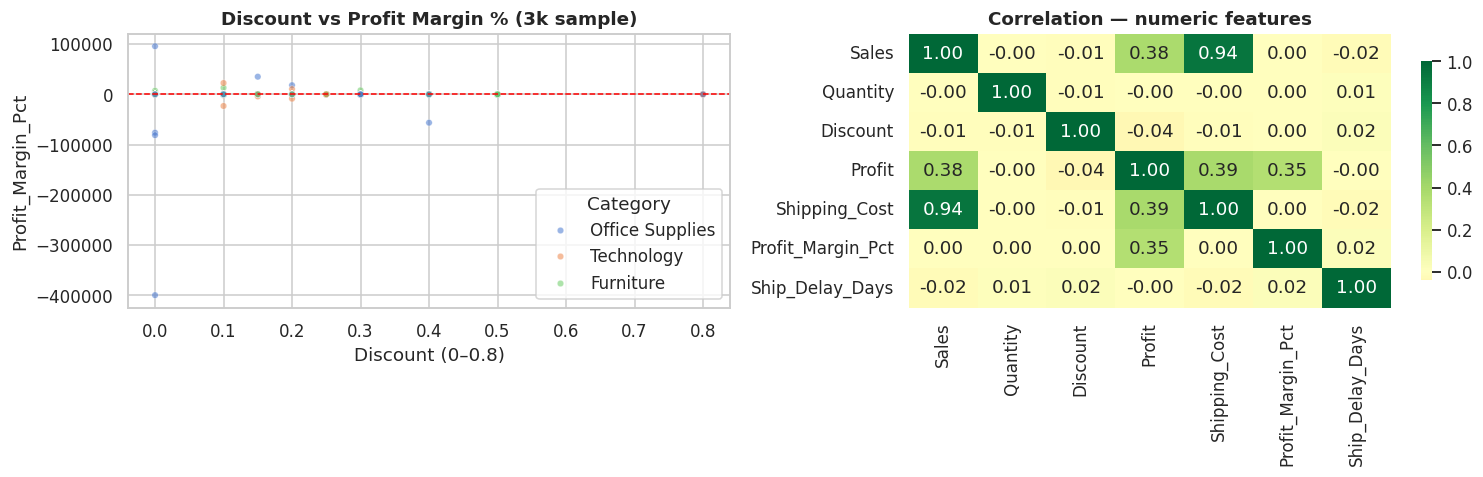

Key correlations with Profit:
Profit               1.00
Shipping_Cost        0.39
Sales                0.38
Profit_Margin_Pct    0.35
Quantity            -0.00
Ship_Delay_Days     -0.00
Discount            -0.04


In [20]:
# --- 10.3 Discount vs Profit & Correlation ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
samp = df.sample(min(3000, len(df)), random_state=42)
sns.scatterplot(data=samp, x="Discount", y="Profit_Margin_Pct", hue="Category", alpha=0.55, s=18, ax=axes[0])
axes[0].set_title("Discount vs Profit Margin % (3k sample)", fontweight="bold")
axes[0].set_xlabel("Discount (0–0.8)")
axes[0].axhline(0, color="red", linestyle="--", linewidth=1)

num_cols = ["Sales","Quantity","Discount","Profit","Shipping_Cost","Profit_Margin_Pct","Ship_Delay_Days"]
corr = df[num_cols].corr().round(2)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", center=0, ax=axes[1], cbar_kws={"shrink":0.8})
axes[1].set_title("Correlation — numeric features", fontweight="bold")
plt.tight_layout()
plt.show()
print("Key correlations with Profit:")
print(corr["Profit"].sort_values(ascending=False).to_string())


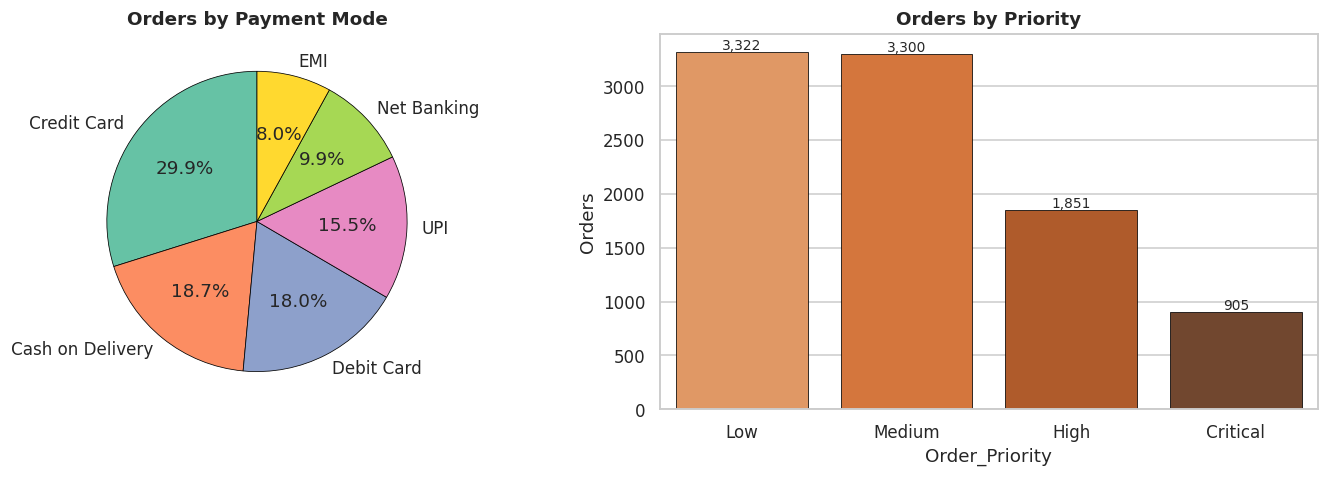

In [21]:
# --- 10.4 Payment mix & Priority mix ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pay = df["Payment_Mode"].value_counts()
axes[0].pie(pay.values, labels=pay.index, autopct="%1.1f%%", startangle=90,
            colors=sns.color_palette("Set2", len(pay)), wedgeprops={"edgecolor":"black", "linewidth":0.5})
axes[0].set_title("Orders by Payment Mode", fontweight="bold")
pri = df["Order_Priority"].value_counts().reindex(["Low","Medium","High","Critical"])
sns.barplot(x=pri.index, y=pri.values, ax=axes[1], palette="Oranges_d", edgecolor="black", linewidth=0.5)
axes[1].set_title("Orders by Priority", fontweight="bold")
axes[1].set_ylabel("Orders")
for i,v in enumerate(pri.values):
    axes[1].text(i, v+20, f"{v:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()


## 11. Export the Final Cleaned Data
Assemble the final column order, sort by date, export `clean_dataset.csv` (relative path), then **reload and verify**.

In [22]:
# --- Final column order ---
final_cols = ["Order_ID","Order_Date","Ship_Date","Ship_Delay_Days","Ship_Date_Fixed","Customer_ID","Customer_Name","Segment",
    "Country","Region","City","State","Postal_Code","Product_ID","Category","Sub_Category","Product_Name",
    "Sales","Quantity","Discount","Profit","Profit_Margin_Pct","Shipping_Cost","Order_Priority","Payment_Mode",
    "Order_Year","Order_Month","Order_Month_Name","Is_Sales_Outlier","Is_Qty_Outlier"]
df_final = df[final_cols].copy().sort_values(["Order_Date","Order_ID"]).reset_index(drop=True)

print(f"Final cleaned shape: {df_final.shape[0]:,} rows × {df_final.shape[1]} columns")
print("\nFinal dtypes:")
print(df_final.dtypes.to_string())
print("\nFinal missing values:")
print(df_final.isna().sum().to_string())
print(f"\nTotal missing cells: {int(df_final.isna().sum().sum()):,}")
print(f"Duplicates: {int(df_final.duplicated().sum())}")

# Export
df_final.to_csv(CLEAN_PATH, index=False)
print(f"\n✅ Exported → {CLEAN_PATH}")

# Reload & verify
check = pd.read_csv(CLEAN_PATH)
print(f"Reload check: {check.shape[0]:,} rows × {check.shape[1]} columns — columns match: {list(check.columns)==final_cols}")
print("\n--- Cleaned head (first 3) ---")
display(df_final.head(3))
print("\n--- Cleaned describe (numeric) ---")
display(df_final[["Sales","Quantity","Discount","Profit","Profit_Margin_Pct","Shipping_Cost","Ship_Delay_Days"]].describe().round(2))


Final cleaned shape: 9,378 rows × 30 columns

Final dtypes:
Order_ID                     object
Order_Date           datetime64[ns]
Ship_Date            datetime64[ns]
Ship_Delay_Days               int64
Ship_Date_Fixed                bool
Customer_ID                  object
Customer_Name                object
Segment                      object
Country                      object
Region                       object
City                         object
State                        object
Postal_Code                  object
Product_ID                   object
Category                     object
Sub_Category                 object
Product_Name                 object
Sales                       float64
Quantity                      int64
Discount                    float64
Profit                      float64
Profit_Margin_Pct           float64
Shipping_Cost               float64
Order_Priority               object
Payment_Mode                 object
Order_Year                    int32
Orde

Reload check: 9,378 rows × 30 columns — columns match: True

--- Cleaned head (first 3) ---


,Order_ID,Order_Date,Ship_Date,Ship_Delay_Days,Ship_Date_Fixed,Customer_ID,Customer_Name,Segment,Country,Region,...,Profit,Profit_Margin_Pct,Shipping_Cost,Order_Priority,Payment_Mode,Order_Year,Order_Month,Order_Month_Name,Is_Sales_Outlier,Is_Qty_Outlier
0,ORD-2021-100646,2021-01-01,2021-01-04,3,False,CUST-11574,Brandon Davis,Home Office,United States,East,...,13889.50,13.40,4045.84,Low,Net Banking,2021,1,Jan,True,False
1,ORD-2021-101904,2021-01-01,2021-01-08,7,False,CUST-10486,Rebecca Taylor,Home Office,United States,East,...,2.22,8.21,6.27,Low,UPI,2021,1,Jan,False,False
2,ORD-2021-103338,2021-01-01,2021-01-06,5,False,CUST-11003,Priya Adams,Consumer,United States,South,...,-0.41,-0.24,9.97,Critical,Debit Card,2021,1,Jan,False,False



--- Cleaned describe (numeric) ---


,Sales,Quantity,Discount,Profit,Profit_Margin_Pct,Shipping_Cost,Ship_Delay_Days
count,9378.00,9378.00,9378.00,9378.00,9378.00,9378.00,9378.00
mean,897.05,5.12,0.10,73.51,-7.66,34.36,3.93
std,6940.46,37.71,0.12,1317.86,5059.01,243.38,2.09
min,5.00,1.00,0.00,-23241.76,-400014.80,2.28,0.00
25%,70.72,1.00,0.00,0.71,0.78,7.42,2.00
50%,175.94,2.00,0.10,8.57,8.10,10.68,4.00
75%,402.34,4.00,0.20,28.59,14.92,17.56,5.00
max,119551.37,950.00,0.80,29715.63,204851.46,5198.70,30.00


## Summary
**What was done:**
- Ingested `retail_orders_raw.csv` (**10,400 rows × 22 columns**, preserved untouched) with missing values, 400 exact duplicates, inconsistent categories (~26 spellings for 3 categories), mixed-type numerics (`$`, `%`, word-numbers), 6+ date formats + invalid dates, and numerical outliers.
- Standardized all text categories to canonical values, coerced numerics/dates to proper dtypes, imputed or dropped missing values with documented business rules, fixed ~900+ ship dates, removed only *impossible* outliers while flagging genuine VIP/bulk orders, and engineered `Order_Year/Month`, `Ship_Delay_Days`, `Profit_Margin_Pct`.
- Compared quality metrics before/after, created trend/composition/correlation visualizations, and exported **`clean_dataset.csv`** — verified by reload.

The cleaned dataset is now **analysis-ready**: no duplicates, no missing cells, valid dtypes, consistent categories, and correct profit margins.
